## **Data Analysis Python Project - Blinkit Analysis**

#### **Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### **Import Raw Data**

In [2]:
df = pd.read_csv('BlinkIT_Grocery_Data_csv.csv')

#### **Sample Data**

In [3]:
df.head(10)

,Item_Fat_Content,Item_Identifier,Item_Type,Outlet_Establishment_Year,Outlet_Identifier,Outlet_Location_Type,Outlet_Size,Outlet_Type,Item_Visibility,Item_Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2014,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,0.00,181.9292,5.0


#### **Size of Data**

In [4]:
df.shape

(8523, 12)

#### **Field Information**

In [5]:
df.columns

Index(['Item_Fat_Content', 'Item_Identifier', 'Item_Type',
       'Outlet_Establishment_Year', 'Outlet_Identifier',
       'Outlet_Location_Type', 'Outlet_Size', 'Outlet_Type', 'Item_Visibility',
       'Item_Weight', 'Sales', 'Rating'],
      dtype='str')

#### **Datatypes**

In [6]:
df.dtypes

Item_Fat_Content                 str
Item_Identifier                  str
Item_Type                        str
Outlet_Establishment_Year      int64
Outlet_Identifier                str
Outlet_Location_Type             str
Outlet_Size                      str
Outlet_Type                      str
Item_Visibility              float64
Item_Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

#### **Data Cleaning**

In [7]:
print(df['Item_Fat_Content'].unique())

<StringArray>
['Regular', 'Low Fat', 'low fat', 'LF', 'reg']
Length: 5, dtype: str


In [8]:
df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({'low fat': 'Low Fat', 
                                                         'LF': 'Low Fat', 
                                                         'reg': 'Regular'})

In [9]:
print(df['Item_Fat_Content'].unique())

<StringArray>
['Regular', 'Low Fat']
Length: 2, dtype: str


In [10]:
df['Item_Fat_Content'].value_counts()

Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

### **Business Requirement**

#### **KPI's Requirements**

In [11]:
# Total Sales
total_sales = df['Sales'].sum()

# Average Sales
avg_sales = df['Sales'].mean()

# No of Items sold
no_of_item_sold = df['Sales'].count()

# Average Rating
avg_rating = df['Rating'].mean()


# Display
print(f"Total Sales: ${total_sales:,.0f}")
print(f"Average Sales: ${avg_sales:,.0f}")
print(f"No of Items sold: ${no_of_item_sold:,.0f}")
print(f"Average Rating: ${avg_rating:.1f}")

Total Sales: $1,201,681
Average Sales: $141
No of Items sold: $8,523
Average Rating: $4.0


# **CHARTS Requirement**

#### **Total Sales by Fat Content**

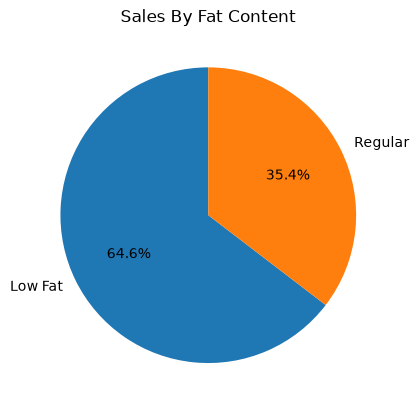

In [12]:
sales_by_fat = df.groupby('Item_Fat_Content')['Sales'].sum()

plt.pie(sales_by_fat , labels = sales_by_fat.index , autopct='%.1f%%' ,
        startangle=90)
plt.title('Sales By Fat Content')

plt.show()

#### **Total Sales by Item Type**

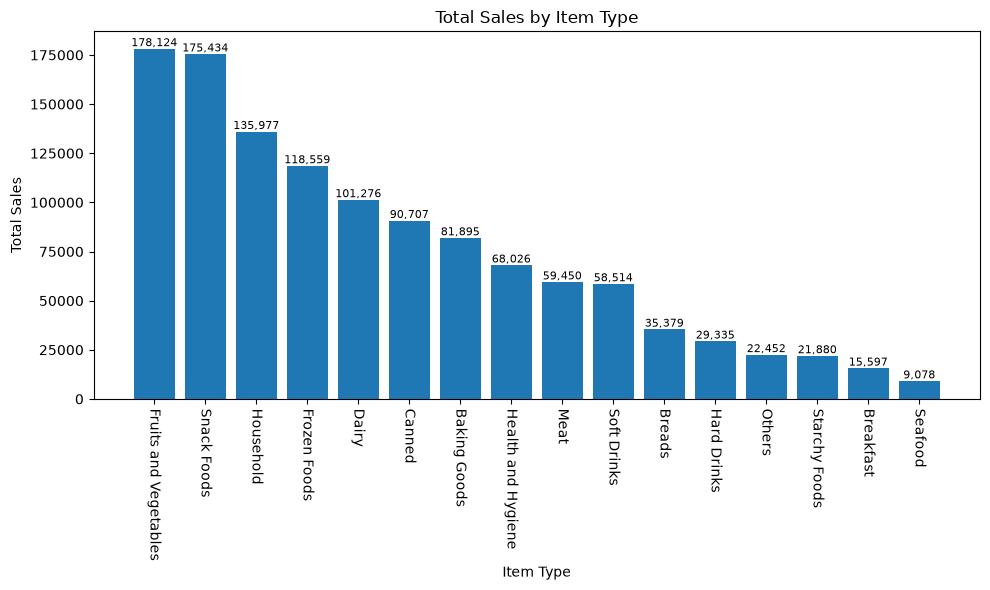

In [13]:
sales_by_item_type = df.groupby('Item_Type')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))
bars = plt.bar(sales_by_item_type.index , sales_by_item_type.values)

plt.xticks(rotation= -90)
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.title('Total Sales by Item Type')

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/ 2, bar.get_height(),
             f'{bar.get_height():,.0f}' , ha='center', va= 'bottom', fontsize=8)


plt.tight_layout()
plt.show()

#### **Fat Content by Outlet for Total Sales**


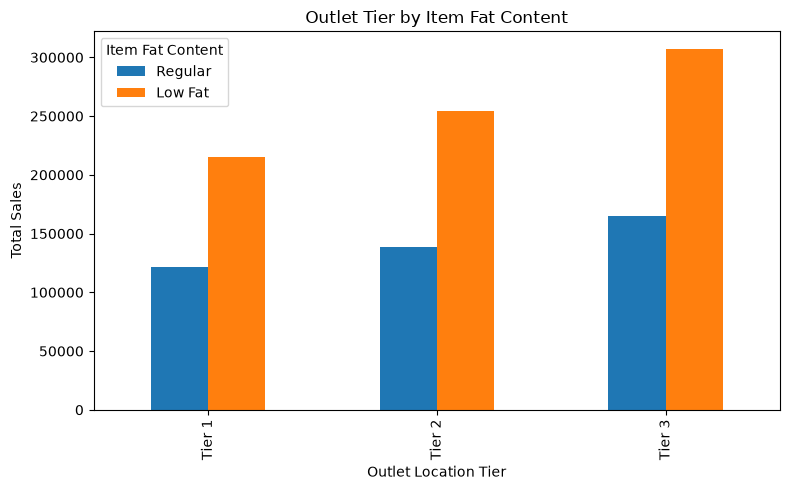

In [14]:
grouped = df.groupby(['Outlet_Location_Type', 'Item_Fat_Content'])['Sales'].sum().unstack()

grouped = grouped[['Regular', 'Low Fat']]

ax = grouped.plot(kind='bar', figsize=(8, 5), title='Outlet Tier by Item Fat Content')
plt.xlabel('Outlet Location Tier')
plt.ylabel('Total Sales')
plt.legend(title='Item Fat Content')
plt.tight_layout()
plt.show()

#### **Total Sales by Outlet Establishment**


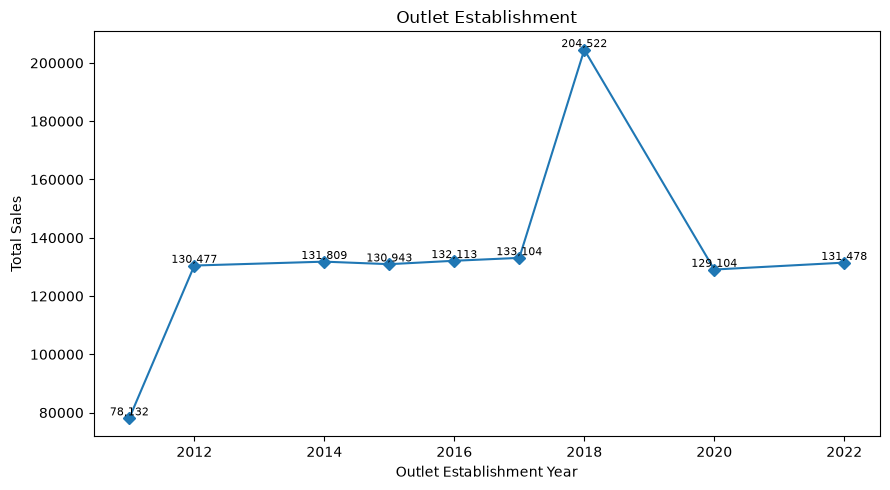

In [18]:
sales_by_year = df.groupby('Outlet_Establishment_Year')['Sales'].sum().sort_index()

plt.figure(figsize=(9,5))
plt.plot(sales_by_year.index , sales_by_year.values , marker='D' , linestyle='-')

plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.title('Outlet Establishment')

for x,y in zip(sales_by_year.index , sales_by_year.values):
    plt.text(x , y , f'{y:,.0f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

#### **Sales by Outlet Size**

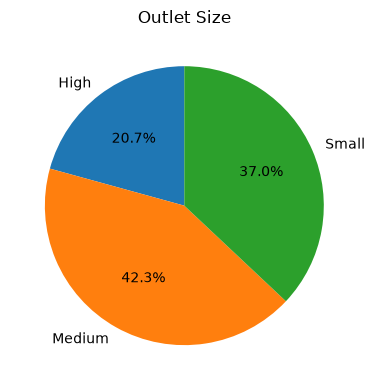

In [24]:
sales_by_outlet_size = df.groupby('Outlet_Size')['Sales'].sum()
# print(sales_by_outlet_size)

plt.figure(figsize=(4 , 4))
plt.pie(sales_by_outlet_size , labels = sales_by_outlet_size.index , 
        autopct='%.1f%%', startangle=90)
plt.title('Outlet Size')
plt.tight_layout()
plt.show()

#### **Sales by Outlet Locations**

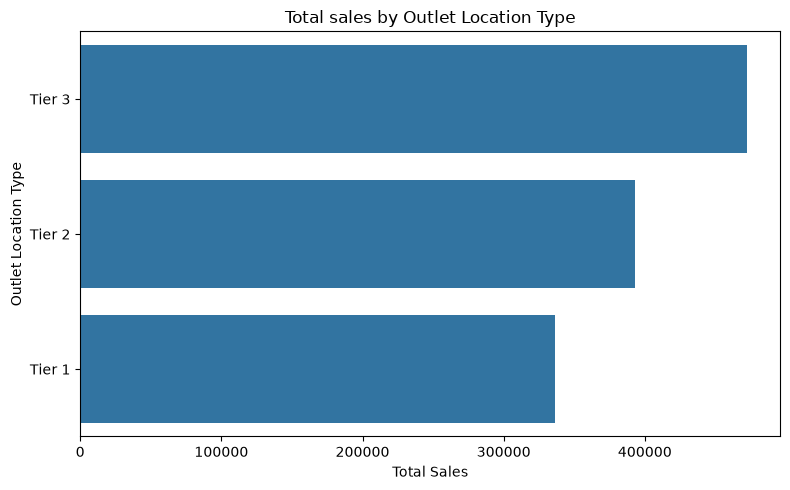

In [36]:
sales_by_location = df.groupby('Outlet_Location_Type')['Sales'].sum().reset_index()
# sales_by_location = df.groupby('Outlet_Location_Type')['Sales'].sum()
sales_by_location = sales_by_location.sort_values('Sales', ascending=False)
# print(sales_by_outlet_size)

plt.figure(figsize=(8 , 5))
ax = sns.barplot(data =sales_by_location , x='Sales', y ='Outlet_Location_Type') 
# plt.barh(sales_by_location.index, sales_by_location.values)
plt.title('Total sales by Outlet Location Type')
plt.xlabel('Total Sales')
plt.ylabel('Outlet Location Type')
plt.tight_layout()
plt.show()